# 10.1: Whose stock market? (FRED)

**Issue #10, cycle 2: The hemline index** (Pillar 5, Trend Forecast, With Receipts)

## What this notebook does

Fashion trends often get read as signals about "the economy," and in practice that
usually means the US stock market (the S&P 500). This notebook asks two follow-up
questions:

1. **Who actually owns the stock market?** The share of all US corporate stocks and
   mutual fund shares held by four wealth groups, from 1989 to today.
2. **Who gets hit hardest when the economy turns?** Unemployment for adults without a
   high school diploma vs. adults with a bachelor's degree or higher, during the
   2008 and 2020 downturns.

US recession dates are also pulled, only to shade the charts.

## Data (all from FRED, Federal Reserve Bank of St. Louis)

| Series ID | What it measures | Frequency |
|---|---|---|
| `WFRBST01122` | Top 1% share of corporate equities and mutual fund shares | Quarterly |
| `WFRBSN09149` | 90th to 99th percentiles' share | Quarterly |
| `WFRBSN40176` | 50th to 90th percentiles' share | Quarterly |
| `WFRBSB50203` | Bottom 50%'s share | Quarterly |
| `LNS14027659` | Unemployment rate, less than a high school diploma, 25+ | Monthly, seasonally adjusted |
| `LNS14027662` | Unemployment rate, bachelor's degree and higher, 25+ | Monthly, seasonally adjusted |
| `USREC` | NBER-based recession indicator (1 = recession) | Monthly |

The wealth shares come from the Federal Reserve Board's Distributional Financial
Accounts. The top 0.1% series is left out on purpose: it sits inside the top 1%, so
including it would count the same households twice.

## Outputs

- `data/raw/cycle 2/issue-10/fred_wealth_shares.csv`
- `data/raw/cycle 2/issue-10/fred_unemployment_education.csv`
- `data/processed/cycle 2/issue-10/recession_periods.csv`
- Exploratory charts only. Branded versions are made in Canva.
- Findings (section 4) feed slide 7 (WHO PAYS) and the LinkedIn caption.

## Notes

- FRED dates each quarter by its first day (e.g. `2026-04-01` is Q2 2026), so quarterly
  results are labelled by quarter, not month.
- October 2025 has no unemployment data in either series. The BLS did not collect
  household survey data that month because of the federal government shutdown, and
  will not collect it retroactively (U.S. Bureau of Labor Statistics, 2025). The gap
  is left as is, not filled in. On the charts, the line connects September to November.
- Only months where both unemployment series have a value are kept, so both end on
  the same month (September 2026).
- The FRED API key is read from `.env` and never written into this notebook.

## 1. Setup

Imports, API key and file paths. The notebook sits three folders below the repo root,
so every path starts with `../../../`. The FRED key is read from `.env` and is never
written into this notebook.

In [1]:
# Force the inline backend first, to avoid the Agg backend conflict hit in Issue #4
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv

# Load FRED_API_KEY from the repo-root .env (gitignored)
load_dotenv("../../../.env")
FRED_API_KEY = os.getenv("FRED_API_KEY")
assert FRED_API_KEY, "FRED_API_KEY not found. Check the .env file at the repo root."

# Paths for this issue
RAW_DIR = Path("../../../data/raw/cycle 2/issue-10")
PROCESSED_DIR = Path("../../../data/processed/cycle 2/issue-10")
PALETTE_PATH = Path("../../../brand/palette.json")

# Fail early if the folders from the mkdir step are missing
for folder in (RAW_DIR, PROCESSED_DIR):
    assert folder.exists(), f"Missing folder: {folder}"

## 2. Load brand palette

In [3]:
# load brand palette
with open("../../../brand/palette.json") as f:
    palette_data = json.load(f)

palette = {c["name"]: c["hex"] for c in palette_data["palette"]}

COCOA = palette["Cocoa"]
DUSTY = palette["Dusty"]
PEACH = palette["Peach"]
CREAM = palette["Cream"]
SAGE  = palette["Sage"]

## 3. Extracting data from FRED

### 3.1 FRED fetch helper

One function pulls any FRED series into a two-column table (date, value).

Two FRED quirks are handled here:
- A bad series ID returns a JSON error message, not an HTTP error. If the response
  has no "observations", the helper prints FRED's own message before stopping.
- Missing values come back as "." rather than blank, so values are converted to
  numbers with anything unreadable set to empty (NaN).

In [4]:
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"

def fetch_fred(series_id, start="1989-01-01"):
    """Pull one FRED series as a DataFrame with columns: date, <series_id>."""
    params = {
        "series_id": series_id,
        "api_key": FRED_API_KEY,
        "file_type": "json",
        "observation_start": start,
    }
    resp = requests.get(FRED_URL, params=params, timeout=30)
    data = resp.json()

    # FRED reports bad IDs inside the JSON, so show its message before failing
    if "observations" not in data:
        print(data)
        raise KeyError(f"No observations returned for {series_id}")

    df = pd.DataFrame(data["observations"])[["date", "value"]]
    df["date"] = pd.to_datetime(df["date"])
    df["value"] = pd.to_numeric(df["value"], errors="coerce")  # "." becomes NaN
    return df.rename(columns={"value": series_id})

### 3.2 Who owns the stock market

Quarterly share of all US corporate stocks and mutual fund shares held by four wealth
groups, from the Federal Reserve's Distributional Financial Accounts. The four groups
cover the whole population, so each quarter should add up to roughly 100%.
That's checked below as a sanity test.

In [5]:
# Four non-overlapping wealth groups (top 0.1% left out: it sits inside the top 1%)
WEALTH_SERIES = {
    "WFRBSB50203": "bottom_50",
    "WFRBSN40176": "p50_90",
    "WFRBSN09149": "p90_99",
    "WFRBST01122": "top_1",
}

# Pull each series and join them on date
wealth = None
for series_id, label in WEALTH_SERIES.items():
    df = fetch_fred(series_id).rename(columns={series_id: label})
    wealth = df if wealth is None else wealth.merge(df, on="date", how="outer")

wealth = wealth.sort_values("date").reset_index(drop=True)

# Sanity check: the four groups should cover about 100% each quarter
wealth["total"] = wealth[list(WEALTH_SERIES.values())].sum(axis=1)
print(wealth["total"].describe())

# Save the raw pull (gitignored folder)
wealth.to_csv(RAW_DIR / "fred_wealth_shares.csv", index=False)

# The latest quarter is the slide 7 candidate
print(wealth.tail(1).T)

count    148.000000
mean     100.000676
std        0.065462
min       99.800000
25%      100.000000
50%      100.000000
75%      100.000000
max      100.100000
Name: total, dtype: float64
                           147
date       2026-04-01 00:00:00
bottom_50                  0.6
p50_90                    11.4
p90_99                    37.2
top_1                     50.9
total                    100.1


In [6]:
# Compare the first and latest quarters, to show whether the split is new or long-standing
groups = list(WEALTH_SERIES.values())
first, latest = wealth.iloc[0], wealth.iloc[-1]

change = pd.DataFrame({
    "first": first[groups],
    "latest": latest[groups],
})
change["change_pts"] = change["latest"] - change["first"]
print(f"First quarter: {first['date'].date()}  |  Latest quarter: {latest['date'].date()}")
print(change)

First quarter: 1989-07-01  |  Latest quarter: 2026-04-01
          first latest change_pts
bottom_50   1.1    0.6       -0.5
p50_90     17.2   11.4       -5.8
p90_99     38.8   37.2       -1.6
top_1      42.8   50.9        8.1


### 3.3 Unemployment by education

Monthly unemployment rate for adults 25 and over, comparing people without a high
school diploma and people with a bachelor's degree or higher. For each downturn:
the rate just before it started, the highest point, how much it rose, and how many
months it took to get back to the starting level.

In [10]:
EDU_SERIES = {
    "LNS14027659": "no_diploma",
    "LNS14027662": "bachelors_plus",
}

jobs = None
for series_id, label in EDU_SERIES.items():
    df = fetch_fred(series_id, start="1992-01-01").rename(columns={series_id: label})
    jobs = df if jobs is None else jobs.merge(df, on="date", how="outer")

jobs = jobs.sort_values("date").reset_index(drop=True)

# Keep only months where both series have a value, so they end on the same month
jobs = jobs.dropna(subset=list(EDU_SERIES.values())).reset_index(drop=True)

print(f"Unemployment data runs {jobs['date'].min().date()} to {jobs['date'].max().date()}")
jobs.to_csv(RAW_DIR / "fred_unemployment_education.csv", index=False)

# (month before the recession, last month to search): each window stops before the next downturn
DOWNTURNS = {
    "2008": ("2007-11-01", "2020-01-01"),
    "2020": ("2020-02-01", "2026-12-01"),
}

def downturn_summary(series, start_date, end_date):
    """Starting rate, peak rate, rise, and months from start back to the starting level,
    searching only within this downturn's window."""
    s = jobs.set_index("date")[series]
    start = pd.Timestamp(start_date)
    base = s.loc[start]
    after = s.loc[start:end_date].dropna()
    peak_date = after.idxmax()
    peak = after.max()

    # First month after the peak when the rate is back at or below the starting level
    recovered = after.loc[peak_date:][after.loc[peak_date:] <= base]

    # First month after the peak when the rate is back at or below the starting level
    recovered = after.loc[peak_date:][after.loc[peak_date:] <= base]
    months_back = None
    if not recovered.empty:
        rec_date = recovered.index[0]
        months_back = (rec_date.year - start.year) * 12 + (rec_date.month - start.month)

    return {
        "start_rate": base,
        "peak_rate": peak,
        "peak_date": peak_date.date(),
        "rise_pts": round(peak - base, 1),
        "months_to_recover": months_back,
    }

rows = []
for name, (start_date, end_date) in DOWNTURNS.items():
    for label in EDU_SERIES.values():
        rows.append({"downturn": name, "group": label, **downturn_summary(label, start_date, end_date)})

print(pd.DataFrame(rows))

Unemployment data runs 1992-01-01 to 2026-09-01
  downturn           group  start_rate  peak_rate   peak_date  rise_pts  \
0     2008      no_diploma         7.7       15.8  2010-02-01       8.1   
1     2008  bachelors_plus         2.2        5.0  2009-09-01       2.8   
2     2020      no_diploma         5.7       21.2  2020-04-01      15.5   
3     2020  bachelors_plus         1.9        8.4  2020-04-01       6.5   

   months_to_recover  
0                 95  
1                119  
2                 21  
3                 25  


### 3.4 Recession dates

Monthly recession indicator (1 = recession, 0 = not), used only to shade charts.
Converted into start and end dates for each recession.

In [12]:
rec = fetch_fred("USREC", start="1989-01-01").rename(columns={"USREC": "recession"})

# Find where the indicator switches on (start) and off (first month after the end)
rec["switch"] = rec["recession"].diff()
starts = rec.loc[rec["switch"] == 1, "date"].tolist()
ends = rec.loc[rec["switch"] == -1, "date"].tolist()
recessions = pd.DataFrame({"start": starts, "end": ends[: len(starts)]})

recessions.to_csv(PROCESSED_DIR / "recession_periods.csv", index=False)
print(recessions)

       start        end
0 1990-08-01 1991-04-01
1 2001-04-01 2001-12-01
2 2008-01-01 2009-07-01
3 2020-03-01 2020-05-01


## 4. Plot

Exploratory charts only, to check the shapes before writing slide copy.
Grey bands mark US recessions. Branded versions are made in Canva.

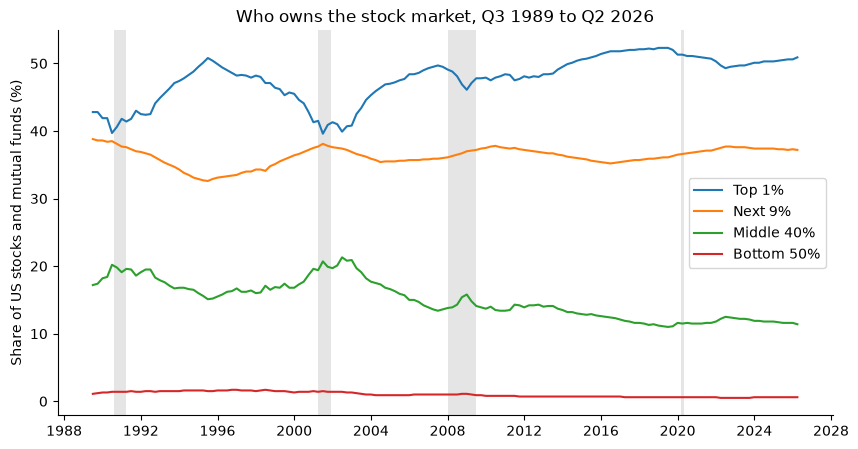

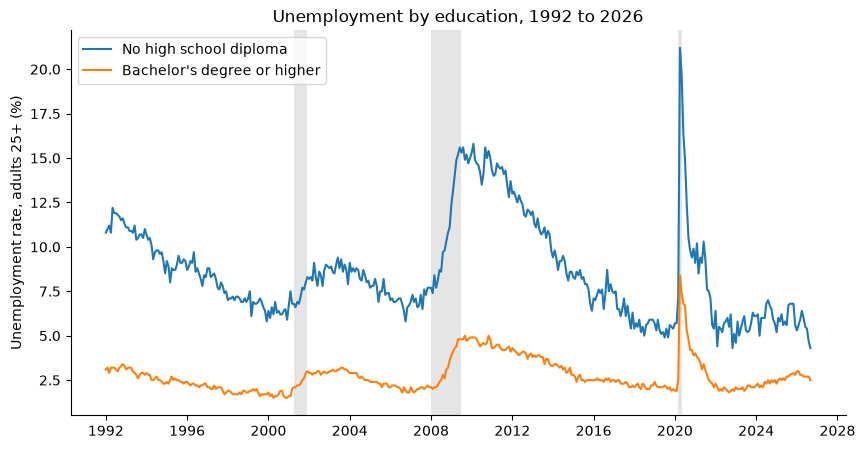

In [13]:
def shade_recessions(ax, start="1989-01-01"):
    """Grey bands for each recession on a date axis."""
    for _, r in recessions.iterrows():
        if r["end"] >= pd.Timestamp(start):
            ax.axvspan(r["start"], r["end"], color="grey", alpha=0.2, lw=0)

# Chart 1: who owns the stock market, 1989 to now
fig, ax = plt.subplots(figsize=(10, 5))
for col, label in [("top_1", "Top 1%"), ("p90_99", "Next 9%"),
                   ("p50_90", "Middle 40%"), ("bottom_50", "Bottom 50%")]:
    ax.plot(wealth["date"], wealth[col], label=label)
shade_recessions(ax)
ax.set_ylabel("Share of US stocks and mutual funds (%)")
ax.set_title("Who owns the stock market, Q3 1989 to Q2 2026")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# Chart 2: unemployment by education, with both downturns
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(jobs["date"], jobs["no_diploma"], label="No high school diploma")
ax.plot(jobs["date"], jobs["bachelors_plus"], label="Bachelor's degree or higher")
shade_recessions(ax, start="1992-01-01")
ax.set_ylabel("Unemployment rate, adults 25+ (%)")
ax.set_title("Unemployment by education, 1992 to 2026")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Findings

### Who owns the stock market (Q2 2026)

| Wealth group | Share of US stocks and mutual funds |
|---|---|
| Top 1% | 50.9% |
| Next 9% (90th to 99th) | 37.2% |
| Middle 40% (50th to 90th) | 11.4% |
| Bottom 50% | 0.6% |

- Per $100 of US stocks: about $51 belongs to the top 1% of households, and about
  60 cents to the bottom half. The top 10% together hold about $88.
- Since Q3 1989: top 1% up from 42.8% to 50.9%. The middle 40% lost the most share
  (17.2% to 11.4%). The bottom 50% was under 2% throughout (1.1% then, 0.6% now).
- Not a steady climb: the top 1% share peaked around 1995 (about 51%), fell to about
  40% around 2002, reached its high of 52.3% in 2019, and dipped to about 49% in 2022.
- The top 1%'s share dips during each recession, then recovers. Observation only,
  not interpreted here.
- Every quarter's four shares sum to between 99.8% and 100.1% (rounding), confirming
  the groups don't overlap.

### Unemployment by education (adults 25+)

| Downturn | Group | Before | Peak | Rise | Back to starting level |
|---|---|---|---|---|---|
| 2008 | No diploma | 7.7% | 15.8% (Feb 2010) | +8.1 pts | 95 months |
| 2008 | Bachelor's+ | 2.2% | 5.0% (Sep 2009) | +2.8 pts | 119 months |
| 2020 | No diploma | 5.7% | 21.2% (Apr 2020) | +15.5 pts | 21 months |
| 2020 | Bachelor's+ | 1.9% | 8.4% (Apr 2020) | +6.5 pts | 25 months |

- Months are counted from the month before the downturn (Nov 2007 or Feb 2020) to
  the first month the rate was back at or below that level.
- At each peak, far more adults without a diploma were out of work: about 1 in 6
  vs. 1 in 20 (2008 to 2010), and about 1 in 5 vs. 1 in 12 (2020).
- Recovery is not the story: degree holders took longer to get back to their
  starting rate both times, because that rate was already very low. In proportion,
  both groups' rates roughly doubled in 2008 and quadrupled in 2020.

### For the slides

- Slide 7 (WHO PAYS): stock ownership carries it. Use the two facts as they are
  ("in 1989, about $43; today, about $51"), not "the gap keeps growing."
- Unemployment: optional, as one supporting line (the 2020 peak, no comparison),
  or LinkedIn caption only.